In [1]:
%pip install pandas numpy matplotlib openpyxl

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    ----------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [6]:
df = pd.read_csv("../data/job_market.Raw.csv")

df.head()

,Job Title,Location,Salary,Monthly Salary,Locality,State
0,Robotics / STEM Trainer,"Indore, Madhya Pradesh","₹1,80,000 - ₹3,60,000 a year",270000.0,NaN,Madhya Pradesh
1,HTML Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
2,Java Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
3,"Teachers - Pre-Primary and Primary (English, M...","Pulivendla, Andhra Pradesh","₹20,000 - ₹30,000 a month",25000.0,NaN,Andhra Pradesh
4,College Student,Remote,"₹15,000 - ₹20,000 a month",17500.0,Remote,Remote


In [7]:
df.shape

(835, 6)

In [8]:
df.columns

Index(['Job Title', 'Location', 'Salary', 'Monthly Salary', 'Locality',
       'State'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Job Title       835 non-null    object 
 1   Location        835 non-null    object 
 2   Salary          835 non-null    object 
 3   Monthly Salary  497 non-null    float64
 4   Locality        254 non-null    object 
 5   State           835 non-null    object 
dtypes: float64(1), object(5)
memory usage: 39.3+ KB


In [10]:
df["Salary"].value_counts(dropna=False).head(30)

Salary
Not specified                   237
₹15,000 - ₹20,000 a month        30
₹10,000 - ₹15,000 a month        19
₹15,000 - ₹25,000 a month        17
₹20,000 - ₹25,000 a month        13
From ₹15,000 a month             12
₹12,000 - ₹15,000 a month        11
₹20,000 - ₹30,000 a month         8
₹15,000 - ₹30,000 a month         8
₹12,000 - ₹25,000 a month         8
From ₹10,000 a month              8
₹18,000 - ₹25,000 a month         7
₹10,000 - ₹12,000 a month         7
₹10,000 - ₹20,000 a month         7
From ₹20,000 a month              7
₹18,000 - ₹35,000 a month         6
₹15,000 - ₹35,000 a month         5
₹13,000 - ₹15,000 a month         5
From ₹12,000 a month              5
₹8,000 - ₹12,000 a month          5
₹8,000 - ₹10,000 a month          5
₹15,000 - ₹45,000 a month         4
₹10,000 - ₹25,000 a month         4
₹7,000 - ₹10,000 a month          4
₹10,000 - ₹13,000 a month         4
₹20,000 - ₹40,000 a month         4
₹8,000 - ₹15,000 a month          4
₹15,000 - ₹18,000 a m

In [11]:
df[["Salary", "Monthly Salary"]].head(30)


,Salary,Monthly Salary
0,"₹1,80,000 - ₹3,60,000 a year",270000.0
1,Not specified,NaN
2,Not specified,NaN
3,"₹20,000 - ₹30,000 a month",25000.0
4,"₹15,000 - ₹20,000 a month",17500.0
5,Not specified,NaN
6,Not specified,NaN
7,Not specified,NaN
8,"₹14,678 - ₹22,689 a month",18683.5
9,"From ₹12,800 a month",NaN


In [12]:
clean_df = df.copy()

clean_df.head()

,Job Title,Location,Salary,Monthly Salary,Locality,State
0,Robotics / STEM Trainer,"Indore, Madhya Pradesh","₹1,80,000 - ₹3,60,000 a year",270000.0,NaN,Madhya Pradesh
1,HTML Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
2,Java Developers - Freshers,"Banaswadi, Bengaluru, Karnataka",Not specified,NaN,Banaswadi,Karnataka
3,"Teachers - Pre-Primary and Primary (English, M...","Pulivendla, Andhra Pradesh","₹20,000 - ₹30,000 a month",25000.0,NaN,Andhra Pradesh
4,College Student,Remote,"₹15,000 - ₹20,000 a month",17500.0,Remote,Remote


In [13]:
import re
import numpy as np

In [14]:
def extract_salary(text):
    text = str(text).lower().strip()
    
    # Not specified
    if text == "not specified" or text == "nan":
        return np.nan, np.nan, "Unknown", "Unknown"
    
    # Extract numbers after removing commas
    numbers = re.findall(r'\d+(?:\.\d+)?', text.replace(",", ""))
    
    numbers = [float(x) for x in numbers]
    
    # Determine period
    if "month" in text:
        period = "Monthly"
    elif "year" in text:
        period = "Annual"
    else:
        period = "Unknown"
    
    # From salary
    if "from" in text and len(numbers) >= 1:
        return numbers[0], np.nan, period, "From"
    
    # Salary range
    if len(numbers) >= 2:
        return numbers[0], numbers[1], period, "Range"
    
    return np.nan, np.nan, period, "Unknown"

In [15]:
clean_df[["Salary_Min", "Salary_Max", "Salary_Period", "Salary_Type"]] = (
    clean_df["Salary"].apply(extract_salary).apply(pd.Series)
)

In [16]:
clean_df[[
    "Salary",
    "Salary_Min",
    "Salary_Max",
    "Salary_Period",
    "Salary_Type"
]].head(20)

,Salary,Salary_Min,Salary_Max,Salary_Period,Salary_Type
0,"₹1,80,000 - ₹3,60,000 a year",180000.0,360000.0,Annual,Range
1,Not specified,NaN,NaN,Unknown,Unknown
2,Not specified,NaN,NaN,Unknown,Unknown
3,"₹20,000 - ₹30,000 a month",20000.0,30000.0,Monthly,Range
4,"₹15,000 - ₹20,000 a month",15000.0,20000.0,Monthly,Range
5,Not specified,NaN,NaN,Unknown,Unknown
6,Not specified,NaN,NaN,Unknown,Unknown
7,Not specified,NaN,NaN,Unknown,Unknown
8,"₹14,678 - ₹22,689 a month",14678.0,22689.0,Monthly,Range
9,"From ₹12,800 a month",12800.0,NaN,Monthly,From


In [18]:
clean_df["Annual_Salary_Min"] = np.where(
    clean_df["Salary_Period"] == "Monthly",
    clean_df["Salary_Min"] * 12,
    clean_df["Salary_Min"]
)

clean_df["Annual_Salary_Max"] = np.where(
    clean_df["Salary_Period"] == "Monthly",
    clean_df["Salary_Max"] * 12,
    clean_df["Salary_Max"]
)

In [19]:
clean_df.columns

Index(['Job Title', 'Location', 'Salary', 'Monthly Salary', 'Locality',
       'State', 'Salary_Min', 'Salary_Max', 'Salary_Period', 'Salary_Type',
       'Annual_Salary_Min', 'Annual_Salary_Max'],
      dtype='object')

In [20]:
clean_df[[
    "Salary",
    "Salary_Min",
    "Salary_Max",
    "Salary_Period",
    "Salary_Type"
]].head(10)

,Salary,Salary_Min,Salary_Max,Salary_Period,Salary_Type
0,"₹1,80,000 - ₹3,60,000 a year",180000.0,360000.0,Annual,Range
1,Not specified,NaN,NaN,Unknown,Unknown
2,Not specified,NaN,NaN,Unknown,Unknown
3,"₹20,000 - ₹30,000 a month",20000.0,30000.0,Monthly,Range
4,"₹15,000 - ₹20,000 a month",15000.0,20000.0,Monthly,Range
5,Not specified,NaN,NaN,Unknown,Unknown
6,Not specified,NaN,NaN,Unknown,Unknown
7,Not specified,NaN,NaN,Unknown,Unknown
8,"₹14,678 - ₹22,689 a month",14678.0,22689.0,Monthly,Range
9,"From ₹12,800 a month",12800.0,NaN,Monthly,From


In [21]:
clean_df["Annual_Salary_Min"] = clean_df["Salary_Min"]

clean_df.loc[
    clean_df["Salary_Period"] == "Monthly",
    "Annual_Salary_Min"
] = clean_df["Salary_Min"] * 12


clean_df["Annual_Salary_Max"] = clean_df["Salary_Max"]

clean_df.loc[
    clean_df["Salary_Period"] == "Monthly",
    "Annual_Salary_Max"
] = clean_df["Salary_Max"] * 12

In [22]:
clean_df["Average_Annual_Salary"] = (
    clean_df["Annual_Salary_Min"] +
    clean_df["Annual_Salary_Max"]
) / 2

In [23]:
clean_df[[
    "Salary",
    "Salary_Period",
    "Salary_Min",
    "Salary_Max",
    "Annual_Salary_Min",
    "Annual_Salary_Max",
    "Average_Annual_Salary"
]].head(20)

,Salary,Salary_Period,Salary_Min,Salary_Max,Annual_Salary_Min,Annual_Salary_Max,Average_Annual_Salary
0,"₹1,80,000 - ₹3,60,000 a year",Annual,180000.0,360000.0,180000.0,360000.0,270000.0
1,Not specified,Unknown,NaN,NaN,NaN,NaN,NaN
2,Not specified,Unknown,NaN,NaN,NaN,NaN,NaN
3,"₹20,000 - ₹30,000 a month",Monthly,20000.0,30000.0,240000.0,360000.0,300000.0
4,"₹15,000 - ₹20,000 a month",Monthly,15000.0,20000.0,180000.0,240000.0,210000.0
5,Not specified,Unknown,NaN,NaN,NaN,NaN,NaN
6,Not specified,Unknown,NaN,NaN,NaN,NaN,NaN
7,Not specified,Unknown,NaN,NaN,NaN,NaN,NaN
8,"₹14,678 - ₹22,689 a month",Monthly,14678.0,22689.0,176136.0,272268.0,224202.0
9,"From ₹12,800 a month",Monthly,12800.0,NaN,153600.0,NaN,NaN


In [27]:
clean_df.isnull().sum()

Job Title                  0
Location                   0
Salary                     0
Monthly Salary           338
Locality                 581
State                      0
Salary_Min               299
Salary_Max               365
Salary_Period              0
Salary_Type                0
Annual_Salary_Min        299
Annual_Salary_Max        365
Average_Annual_Salary    365
dtype: int64

In [24]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Job Title              835 non-null    object 
 1   Location               835 non-null    object 
 2   Salary                 835 non-null    object 
 3   Monthly Salary         497 non-null    float64
 4   Locality               254 non-null    object 
 5   State                  835 non-null    object 
 6   Salary_Min             536 non-null    float64
 7   Salary_Max             470 non-null    float64
 8   Salary_Period          835 non-null    object 
 9   Salary_Type            835 non-null    object 
 10  Annual_Salary_Min      536 non-null    float64
 11  Annual_Salary_Max      470 non-null    float64
 12  Average_Annual_Salary  470 non-null    float64
dtypes: float64(6), object(7)
memory usage: 84.9+ KB


In [25]:
clean_df.duplicated().sum()

5

In [26]:
clean_df[clean_df.duplicated(keep=False)]

,Job Title,Location,Salary,Monthly Salary,Locality,State,Salary_Min,Salary_Max,Salary_Period,Salary_Type,Annual_Salary_Min,Annual_Salary_Max,Average_Annual_Salary
28,Receptionist,"Thrissur, Kerala",Not specified,NaN,NaN,Kerala,NaN,NaN,Unknown,Unknown,NaN,NaN,NaN
69,Front Office,"Kochi, Kerala","₹20,000 - ₹25,000 a month",22500.0,NaN,Kerala,20000.0,25000.0,Monthly,Range,240000.0,300000.0,270000.0
217,Receptionist,"Thrissur, Kerala",Not specified,NaN,NaN,Kerala,NaN,NaN,Unknown,Unknown,NaN,NaN,NaN
281,Organic Chemist - Trainee - 2024,"Ahmedabad, Gujarat",Not specified,NaN,NaN,Gujarat,NaN,NaN,Unknown,Unknown,NaN,NaN,NaN
282,Organic Chemist - Trainee - 2024,"Ahmedabad, Gujarat",Not specified,NaN,NaN,Gujarat,NaN,NaN,Unknown,Unknown,NaN,NaN,NaN
638,Trainee Auditor,"Mangalore, Karnataka","₹16,500 - ₹20,000 a month",18250.0,NaN,Karnataka,16500.0,20000.0,Monthly,Range,198000.0,240000.0,219000.0
660,Front Office,"Kochi, Kerala","₹20,000 - ₹25,000 a month",22500.0,NaN,Kerala,20000.0,25000.0,Monthly,Range,240000.0,300000.0,270000.0
680,Trainee Auditor,"Mangalore, Karnataka","₹16,500 - ₹20,000 a month",18250.0,NaN,Karnataka,16500.0,20000.0,Monthly,Range,198000.0,240000.0,219000.0
747,Badminton Coach,"Bengaluru, Karnataka","From ₹20,000 a month",NaN,NaN,Karnataka,20000.0,NaN,Monthly,From,240000.0,NaN,NaN
748,Badminton Coach,"Bengaluru, Karnataka","From ₹20,000 a month",NaN,NaN,Karnataka,20000.0,NaN,Monthly,From,240000.0,NaN,NaN


In [27]:
text_columns = ["Job Title", "Location", "Locality", "State"]

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
    )

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [32]:
clean_df["State"].value_counts()

State
Kerala                    161
Tamil Nadu                148
Karnataka                 106
Remote                     89
Maharashtra                78
Delhi                      42
Gujarat                    40
Uttar Pradesh              27
Telangana                  20
West Bengal                18
Rajasthan                  15
Madhya Pradesh             14
Haryana                    10
India                       9
Punjab                      9
Andhra Pradesh              7
Himachal Pradesh            7
Chandigarh                  6
Orissa                      5
Goa                         4
Uttarakhand                 4
Chhattisgarh                3
Puducherry                  3
Assam                       3
Bihar                       2
Jharkhand                   2
Jammu and Kashmir           1
Arunachal Pradesh           1
Dadra and Nagar Haveli      1
Name: count, dtype: Int64

In [28]:
clean_df["Job Title"].value_counts().head(30)

Job Title
Delivery Partner/Delivery Executive     9
Video Editor                            8
Trainee                                 8
Business Development Associate          8
Management Trainee                      6
Data Entry Operator                     5
Software Trainee                        5
Assistant Supervisor                    4
Accounts Assistant                      4
Digital Marketing Intern                4
Graduate Trainee                        4
Delivery Executive/Delivery Partner     4
Business Development Executive (BDE)    3
Front Office                            3
Content Creator                         3
Project Manager                         3
Office Assistant                        3
HR Trainee                              3
Billing Executive                       3
Data Analyst                            3
Social Media Manager                    3
Receptionist                            3
Quality Analyst                         3
Cashier                 

In [29]:
clean_df.to_csv("../data/job_market_cleaned.csv", index=False)

print("✅ Cleaned dataset saved!")
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

✅ Cleaned dataset saved!
Rows: 835
Columns: 13


In [30]:
text_columns = ["Job Title", "Location", "Locality", "State"]

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
    )

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [31]:
clean_df["State"].value_counts()

State
Kerala                    161
Tamil Nadu                148
Karnataka                 106
Remote                     89
Maharashtra                78
Delhi                      42
Gujarat                    40
Uttar Pradesh              27
Telangana                  20
West Bengal                18
Rajasthan                  15
Madhya Pradesh             14
Haryana                    10
India                       9
Punjab                      9
Andhra Pradesh              7
Himachal Pradesh            7
Chandigarh                  6
Orissa                      5
Goa                         4
Uttarakhand                 4
Chhattisgarh                3
Puducherry                  3
Assam                       3
Bihar                       2
Jharkhand                   2
Jammu and Kashmir           1
Arunachal Pradesh           1
Dadra and Nagar Haveli      1
Name: count, dtype: Int64

In [32]:
clean_df["Job Title"].value_counts().head(30)

Job Title
Delivery Partner/Delivery Executive     9
Video Editor                            8
Trainee                                 8
Business Development Associate          8
Management Trainee                      6
Data Entry Operator                     5
Software Trainee                        5
Assistant Supervisor                    4
Accounts Assistant                      4
Digital Marketing Intern                4
Graduate Trainee                        4
Delivery Executive/Delivery Partner     4
Business Development Executive (BDE)    3
Front Office                            3
Content Creator                         3
Project Manager                         3
Office Assistant                        3
HR Trainee                              3
Billing Executive                       3
Data Analyst                            3
Social Media Manager                    3
Receptionist                            3
Quality Analyst                         3
Cashier                 

In [33]:
clean_df.to_csv("../data/job_market_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [34]:
clean_df.shape

(835, 13)

In [35]:
clean_df.describe()

,Monthly Salary,Salary_Min,Salary_Max,Annual_Salary_Min,Annual_Salary_Max,Average_Annual_Salary
count,497.000000,5.360000e+02,4.700000e+02,5.360000e+02,4.700000e+02,4.700000e+02
mean,63087.595050,4.406658e+04,7.069836e+04,2.003949e+05,3.352543e+05,2.662024e+05
std,126922.462764,1.180970e+05,1.547388e+05,2.191507e+05,3.381398e+05,2.714459e+05
min,180.000000,8.000000e+00,1.000000e+01,8.000000e+00,1.000000e+01,9.000000e+00
25%,14000.000000,1.000000e+04,1.662500e+04,1.200000e+05,1.920000e+05,1.621250e+05
50%,19250.000000,1.500000e+04,2.500000e+04,1.800000e+05,2.677786e+05,2.220000e+05
75%,28000.000000,2.000000e+04,3.500000e+04,2.177070e+05,3.617392e+05,2.974266e+05
max,939847.175000,2.000000e+06,1.560207e+06,3.000000e+06,4.200000e+06,3.600000e+06


In [36]:
state_jobs = clean_df["State"].value_counts()

state_jobs

State
Kerala                    161
Tamil Nadu                148
Karnataka                 106
Remote                     89
Maharashtra                78
Delhi                      42
Gujarat                    40
Uttar Pradesh              27
Telangana                  20
West Bengal                18
Rajasthan                  15
Madhya Pradesh             14
Haryana                    10
India                       9
Punjab                      9
Andhra Pradesh              7
Himachal Pradesh            7
Chandigarh                  6
Orissa                      5
Goa                         4
Uttarakhand                 4
Chhattisgarh                3
Puducherry                  3
Assam                       3
Bihar                       2
Jharkhand                   2
Jammu and Kashmir           1
Arunachal Pradesh           1
Dadra and Nagar Haveli      1
Name: count, dtype: Int64

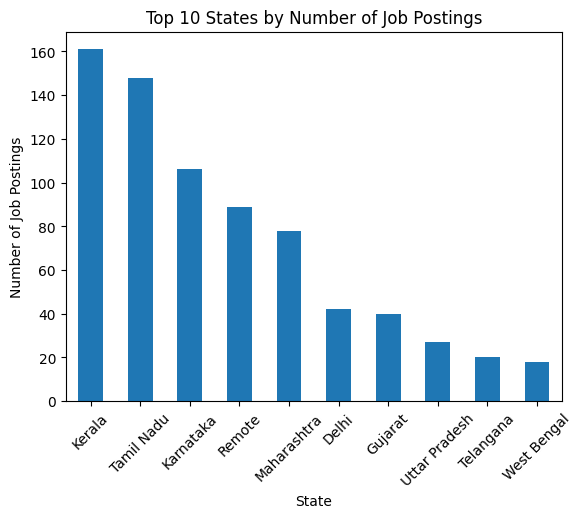

In [37]:
import matplotlib.pyplot as plt

state_jobs.head(10).plot(kind="bar")

plt.title("Top 10 States by Number of Job Postings")
plt.xlabel("State")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.show()

In [38]:
top_jobs = clean_df["Job Title"].value_counts().head(15)

top_jobs

Job Title
Delivery Partner/Delivery Executive     9
Video Editor                            8
Trainee                                 8
Business Development Associate          8
Management Trainee                      6
Data Entry Operator                     5
Software Trainee                        5
Assistant Supervisor                    4
Accounts Assistant                      4
Digital Marketing Intern                4
Graduate Trainee                        4
Delivery Executive/Delivery Partner     4
Business Development Executive (BDE)    3
Front Office                            3
Content Creator                         3
Name: count, dtype: Int64

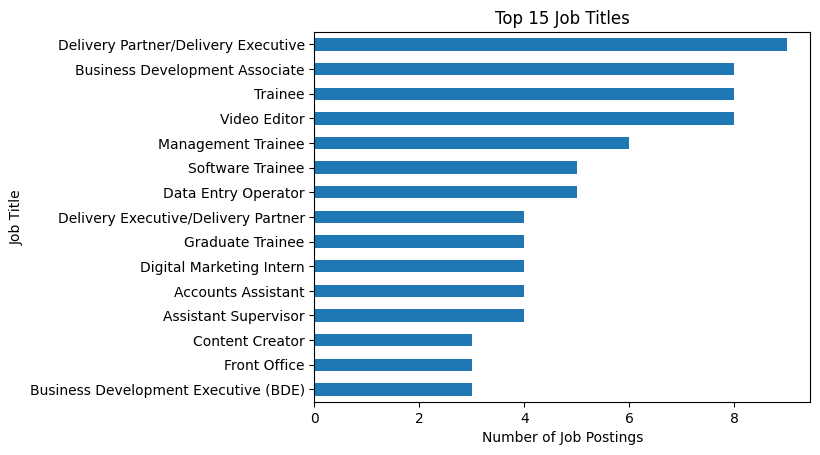

In [39]:
top_jobs.sort_values().plot(kind="barh")

plt.title("Top 15 Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")
plt.show()

In [40]:
salary_info = clean_df["Salary_Type"].value_counts()

salary_info

Salary_Type
Range      470
Unknown    299
From        66
Name: count, dtype: int64

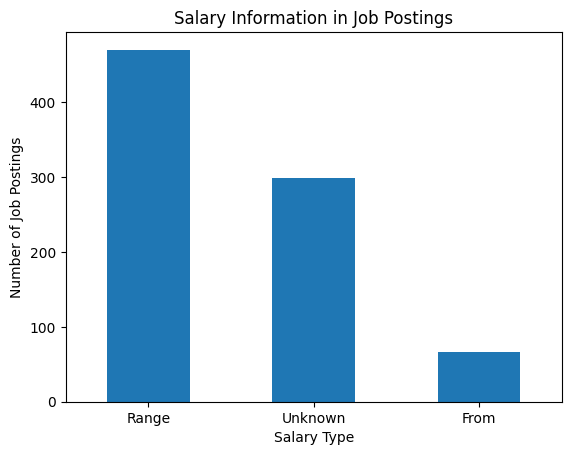

In [41]:
salary_info.plot(kind="bar")

plt.title("Salary Information in Job Postings")
plt.xlabel("Salary Type")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=0)
plt.show()

In [42]:
salary_df = clean_df[
    clean_df["Average_Annual_Salary"].notna()
].copy()

In [43]:
salary_df["Average_Annual_Salary"].describe()

count    4.700000e+02
mean     2.662024e+05
std      2.714459e+05
min      9.000000e+00
25%      1.621250e+05
50%      2.220000e+05
75%      2.974266e+05
max      3.600000e+06
Name: Average_Annual_Salary, dtype: float64

In [44]:
analytics_keywords = [
    "data analyst",
    "business analyst",
    "bi analyst",
    "business intelligence",
    "reporting analyst",
    "mis",
    "data analytics",
    "analytics analyst"
]

In [45]:
pattern = "|".join(analytics_keywords)

analytics_jobs = clean_df[
    clean_df["Job Title"]
    .str.lower()
    .str.contains(pattern, na=False)
].copy()

In [46]:
print("Analytics-related jobs:", len(analytics_jobs))

Analytics-related jobs: 23


In [47]:
analytics_jobs["Job Title"].value_counts().head(20)

Job Title
Data Analyst                                                          3
Organic Chemist - Trainee - 2024                                      2
Junior Business Analyst                                               1
Fresher - Business Analyst                                            1
STUDY ABROAD Admission Process Associate                              1
Admission Counselor/ Telecaler Executive                              1
Urgent Requirements of CHEMISTRY Teacher for NEET & JEE Main level    1
Looking for Course Counsellors/Tele callers on Commission Basis       1
Business Analyst Fresher                                              1
Business Analyst with an Experienced and Freshers also                1
Fresher 2023 | Business Analyst                                       1
Contract Data Analyst                                                 1
Trainee - Junior Data Analyst                                         1
Business Analyst                                      

In [48]:
analytics_locations = analytics_jobs["State"].value_counts()

analytics_locations.head(10)

State
Tamil Nadu        8
Maharashtra       5
Puducherry        2
Gujarat           2
Kerala            2
Andhra Pradesh    1
Karnataka         1
Telangana         1
Chandigarh        1
Name: count, dtype: Int64

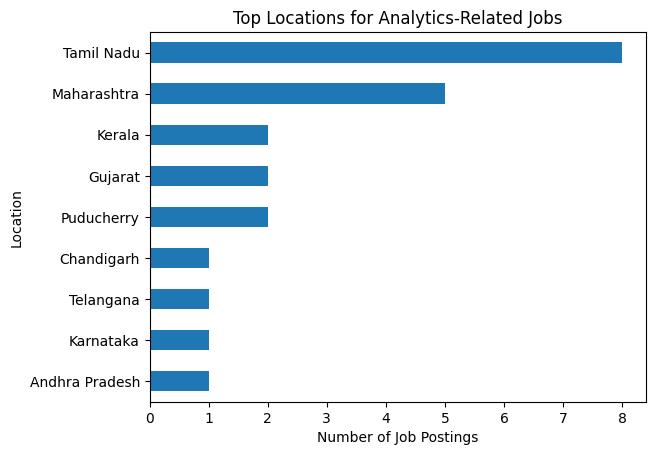

In [49]:
analytics_locations.head(10).sort_values().plot(kind="barh")

plt.title("Top Locations for Analytics-Related Jobs")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.show()

In [50]:
analytics_salary = analytics_jobs[
    analytics_jobs["Average_Annual_Salary"].notna()
].copy()

In [51]:
analytics_salary["Average_Annual_Salary"].describe()

count         9.000000
mean     314412.333333
std      164731.229337
min      120000.000000
25%      198711.000000
50%      285000.000000
75%      450000.000000
max      600000.000000
Name: Average_Annual_Salary, dtype: float64

In [52]:
print("All jobs:", len(clean_df))
print("Analytics-related jobs:", len(analytics_jobs))

All jobs: 835
Analytics-related jobs: 23


In [53]:
print(
    "Analytics job percentage:",
    round(len(analytics_jobs) / len(clean_df) * 100, 2),
    "%"
)

Analytics job percentage: 2.75 %


In [54]:
analytics_jobs.to_csv(
    "../data/analytics_jobs.csv",
    index=False
)

print("✅ Analytics jobs dataset saved!")

✅ Analytics jobs dataset saved!


In [55]:
len(clean_df)

835

In [56]:
clean_df.to_csv("../data/job_market_cleaned.csv", index=False)

In [57]:
test_df = pd.read_csv("../data/job_market_cleaned.csv")

print("Rows:", len(test_df))
print("Columns:", len(test_df.columns))

Rows: 835
Columns: 13


In [58]:
clean_df.dtypes

Job Title                string[python]
Location                 string[python]
Salary                           object
Monthly Salary                  float64
Locality                 string[python]
State                    string[python]
Salary_Min                      float64
Salary_Max                      float64
Salary_Period                    object
Salary_Type                      object
Annual_Salary_Min               float64
Annual_Salary_Max               float64
Average_Annual_Salary           float64
dtype: object

In [59]:
clean_df.shape

(835, 13)

In [60]:
import pandas as pd
import numpy as np

sql_file = "../sql/job_market_insert.sql"

with open(sql_file, "w", encoding="utf-8") as f:
    f.write("USE job_market_intelligence;\n\n")
    
    f.write("""
CREATE TABLE job_postings (
    job_title VARCHAR(255),
    location VARCHAR(255),
    salary TEXT,
    monthly_salary DOUBLE,
    locality VARCHAR(255),
    state VARCHAR(100),
    salary_min DOUBLE,
    salary_max DOUBLE,
    salary_period VARCHAR(50),
    salary_type VARCHAR(50),
    annual_salary_min DOUBLE,
    annual_salary_max DOUBLE,
    average_annual_salary DOUBLE
);

""")

    for _, row in clean_df.iterrows():
        values = []
        
        for col in clean_df.columns:
            value = row[col]
            
            if pd.isna(value):
                values.append("NULL")
            elif isinstance(value, (int, float, np.integer, np.floating)):
                values.append(str(value))
            else:
                value = str(value).replace("\\", "\\\\").replace("'", "''")
                values.append(f"'{value}'")
        
        f.write(
            "INSERT INTO job_postings VALUES ("
            + ", ".join(values)
            + ");\n"
        )

print("SQL file created successfully!")
print("Rows to insert:", len(clean_df))

SQL file created successfully!
Rows to insert: 835
